# TIME SERIES FORECASTING — LAB EXERCISES 4 & 5
## ARIMA Model Implementation and Seasonal ARIMA (SARIMA) Forecasting

**Name:** Chetana S 

**USN / Roll No.:** 1RUA24CSE0107

**Section:** G


## PART A — COMMON CONCEPTS

### 1. Time Series
A time series is a sequence of observations recorded in chronological order. Examples include monthly sales, electricity demand, passenger counts and sensor measurements.

A useful decomposition is:

**Observed = Trend + Seasonality + Cyclical component + Noise**

### 2. Stationarity
A stationary time series has statistical properties that do not systematically change over time. Trend, changing variance and seasonality can make a series non-stationary. ARIMA models generally require the series to be made approximately stationary through differencing.

### 3. Differencing
First-order differencing is:

\[
y'_t = y_t - y_{t-1}
\]

The number of non-seasonal differences is represented by **d**.

### 4. ACF and PACF
- **ACF (Autocorrelation Function):** measures correlation between observations and their lagged values. It helps suggest q (and seasonal Q).
- **PACF (Partial Autocorrelation Function):** measures correlation at a lag after accounting for intermediate lags. It helps suggest p (and seasonal P).

These are guidelines; model selection should also consider AIC/BIC, residual diagnostics and test-set performance.

# LAB EXERCISE 4 — ARIMA MODEL IMPLEMENTATION AND FORECASTING

## 1. Aim
To implement an ARIMA model on a real time-series dataset, prepare the series for modelling, fit the model, generate forecasts, evaluate the forecasts against unseen test data and interpret the results.

## 2. Theory
ARIMA stands for **AutoRegressive Integrated Moving Average** and is represented as **ARIMA(p,d,q)**:
- **p:** order of the AutoRegressive component.
- **d:** number of non-seasonal differences.
- **q:** order of the Moving Average component.

The AR component uses previous observations, the MA component uses previous forecast errors, and the Integrated component represents differencing.

## 3. Dataset
The AirPassengers dataset contains monthly international airline passenger counts from January 1949 to December 1960. It is useful for demonstrating trend and seasonality.

## 4. Required Packages
Install these packages if they are not already available:

`pip install pandas numpy matplotlib statsmodels scikit-learn`

## 5. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (10, 4)

## 6. Load and Inspect the AirPassengers Dataset

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")
series = df["Passengers"].astype(float)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nDate range:", series.index.min(), "to", series.index.max())
print("\nMissing values:", series.isna().sum())

            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

Dataset shape: (144, 1)

Date range: 1949-01-01 00:00:00 to 1960-12-01 00:00:00

Missing values: 0


## 7. Plot the Original Time Series

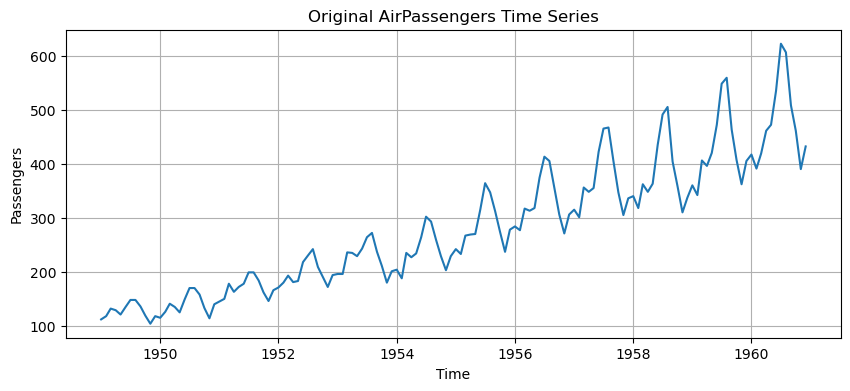

In [3]:
plt.figure()
plt.plot(series)
plt.title("Original AirPassengers Time Series")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

**Observation:** The series shows an overall upward trend and recurring yearly peaks and troughs. This indicates that the original series is not stationary and contains seasonal behaviour.

## 8. Check Stationarity Using the Augmented Dickey-Fuller (ADF) Test

In [4]:
adf_result = adfuller(series)
print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The series is stationary at the 5% significance level.")
else:
    print("The series is non-stationary at the 5% significance level.")

ADF statistic: 0.8153688792060472
p-value: 0.991880243437641
The series is non-stationary at the 5% significance level.


## 9. Apply First-Order Differencing

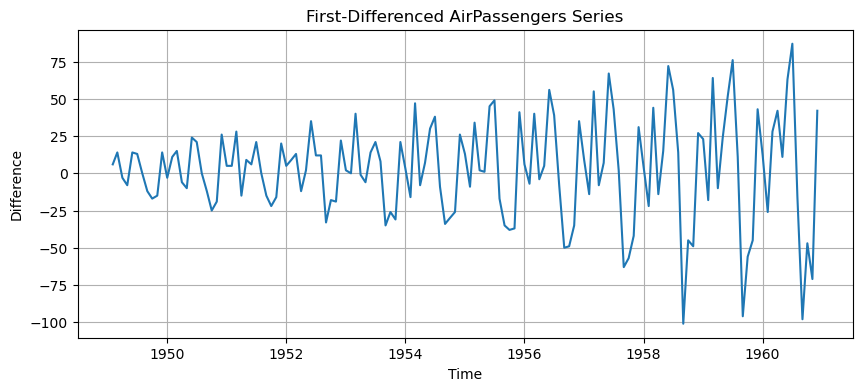

In [5]:
diff_series = series.diff().dropna()

plt.figure()
plt.plot(diff_series)
plt.title("First-Differenced AirPassengers Series")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid(True)
plt.show()

**Observation:** First-order differencing reduces the trend by calculating the change between consecutive monthly observations. The transformed series fluctuates around a more stable level, although seasonal patterns may remain.

## 10. Plot ACF and PACF

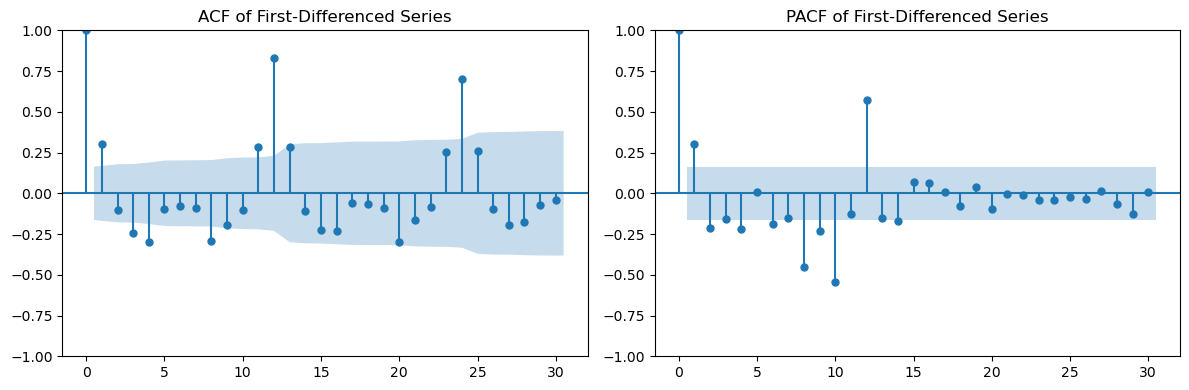

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_series, ax=axes[0], lags=30)
plot_pacf(diff_series, ax=axes[1], lags=30, method="ywm")
axes[0].set_title("ACF of First-Differenced Series")
axes[1].set_title("PACF of First-Differenced Series")
plt.tight_layout()
plt.show()

**Observation:** ACF and PACF plots show the autocorrelation structure of the differenced series. They help identify candidate values for q and p respectively. The plots are used as guidance rather than as an automatic selection rule.

## 11. Train-Test Split (80:20)

In [7]:
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 115
Testing observations: 29
Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


## 12. Fit the ARIMA(2,1,2) Model

In [8]:
arima_model = ARIMA(train, order=(2, 1, 2))
arima_fit = arima_model.fit()

print(arima_fit.summary())

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Sun, 01 Nov 2026   AIC                           1057.516
Time:                        20:58:05   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

## 13. Forecast the Test Period and Evaluate the Model

In [9]:
arima_forecast = arima_fit.forecast(steps=len(test))

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))

print("ARIMA order: (2, 1, 2)")
print("MAE:", arima_mae)
print("RMSE:", arima_rmse)

ARIMA order: (2, 1, 2)
MAE: 63.54531127690957
RMSE: 82.51301133837681


## 14. Plot Actual Values vs ARIMA Forecast

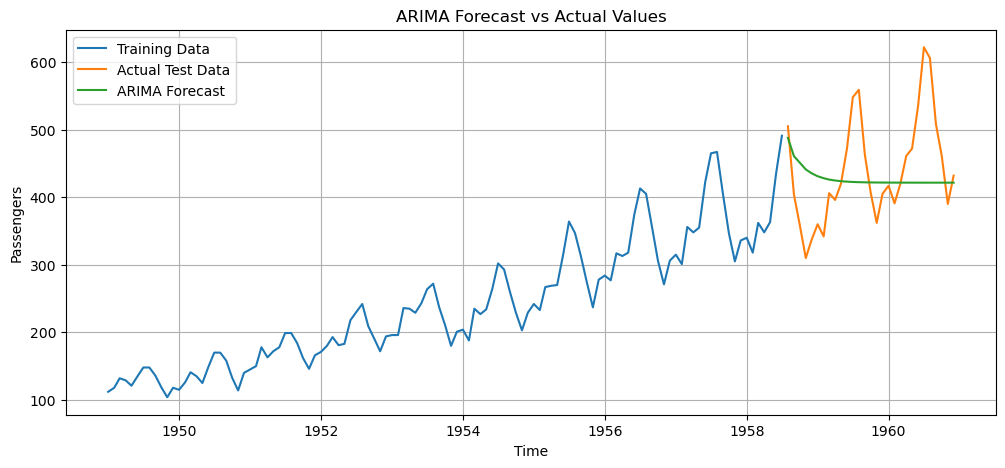

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Test Data")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast")
plt.title("ARIMA Forecast vs Actual Values")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()

## 15. Residual Analysis

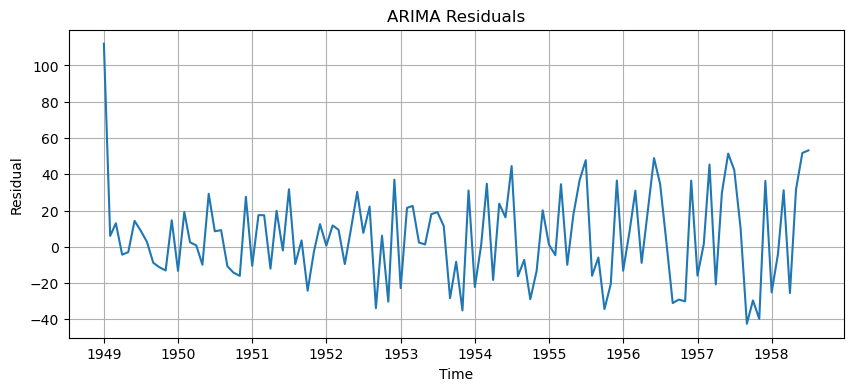

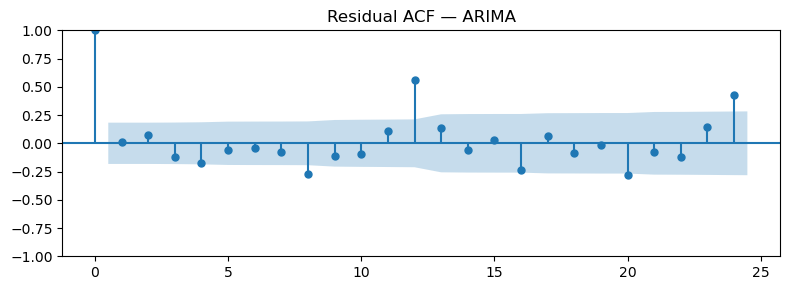

In [11]:
arima_residuals = arima_fit.resid

plt.figure()
plt.plot(arima_residuals)
plt.title("ARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
plot_acf(arima_residuals.dropna(), ax=ax, lags=24)
ax.set_title("Residual ACF — ARIMA")
plt.tight_layout()
plt.show()

**Observation:** Residuals represent the difference between observed and fitted values. Ideally, they should fluctuate randomly around zero without a clear pattern. Significant spikes in the residual ACF may indicate remaining autocorrelation and scope for improving the model.

## 16. Independent Task 4.1 — Compare ARIMA Orders

In [12]:
arima_orders = [(1, 1, 1), (2, 1, 1), (1, 1, 2), (2, 1, 2)]
arima_comparison = []

for order in arima_orders:
    fit = ARIMA(train, order=order).fit()
    prediction = fit.forecast(steps=len(test))
    mae = mean_absolute_error(test, prediction)
    rmse = np.sqrt(mean_squared_error(test, prediction))
    arima_comparison.append({
        "ARIMA Order": str(order),
        "AIC": fit.aic,
        "MAE": mae,
        "RMSE": rmse
    })

arima_comparison_df = pd.DataFrame(arima_comparison)
display(arima_comparison_df)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  

,ARIMA Order,AIC,MAE,RMSE
0,"(1, 1, 1)",1058.245574,85.254156,97.499620
1,"(2, 1, 1)",1058.647616,60.528996,82.621097
2,"(1, 1, 2)",1057.327535,62.063473,82.635764
3,"(2, 1, 2)",1057.516178,63.545311,82.513011


## 17. Independent Task 4.2 — Effect of Differencing (d=0 vs d=1)

In [13]:
differencing_results = []

for d in [0, 1]:
    fit = ARIMA(train, order=(2, d, 2)).fit()
    prediction = fit.forecast(steps=len(test))
    differencing_results.append({
        "d": d,
        "AIC": fit.aic,
        "MAE": mean_absolute_error(test, prediction),
        "RMSE": np.sqrt(mean_squared_error(test, prediction))
    })

display(pd.DataFrame(differencing_results))

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  

,d,AIC,MAE,RMSE
0,0,1074.541308,92.256516,114.904025
1,1,1057.516178,63.545311,82.513011


**Explanation:** When a series is non-stationary, using d=0 may leave its trend unmodelled and can produce poor forecasts. Setting d=1 applies first-order differencing to reduce the trend. The metrics should be compared on the same test set.

## 18. Independent Task 4.3 — Compare Forecast Horizons (6, 12 and 24 Months)

In [14]:
horizon_results = []

for horizon in [6, 12, 24]:
    fit = ARIMA(train, order=(2, 1, 2)).fit()
    prediction = fit.forecast(steps=horizon)
    actual = test.iloc[:horizon]
    horizon_results.append({
        "Forecast Horizon": horizon,
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction))
    })

display(pd.DataFrame(horizon_results))

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  

,Forecast Horizon,MAE,RMSE
0,6,77.787203,85.580588
1,12,64.981969,76.774798
2,24,62.102709,79.918805


**Explanation:** Forecast uncertainty generally increases as the forecast horizon becomes longer because predictions depend increasingly on previously forecast values rather than newly observed data.

## 19. Independent Task 4.4 — Residual ACF

The residual ACF plot was generated in Section 15. It is used to check whether autocorrelation remains after fitting the ARIMA model. If many spikes lie outside the confidence bounds, the residuals may not behave like white noise.

## 20. Independent Task 4.5 — Apply ARIMA to a Different Real Dataset (Sunspots)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


Dataset: Sunspots (statsmodels built-in dataset)
Frequency: Annual
Total observations: 309
Training observations: 247
Testing observations: 62
Selected order: (2, 1, 2)
MAE: 33.161260578897846
RMSE: 40.227838134650504


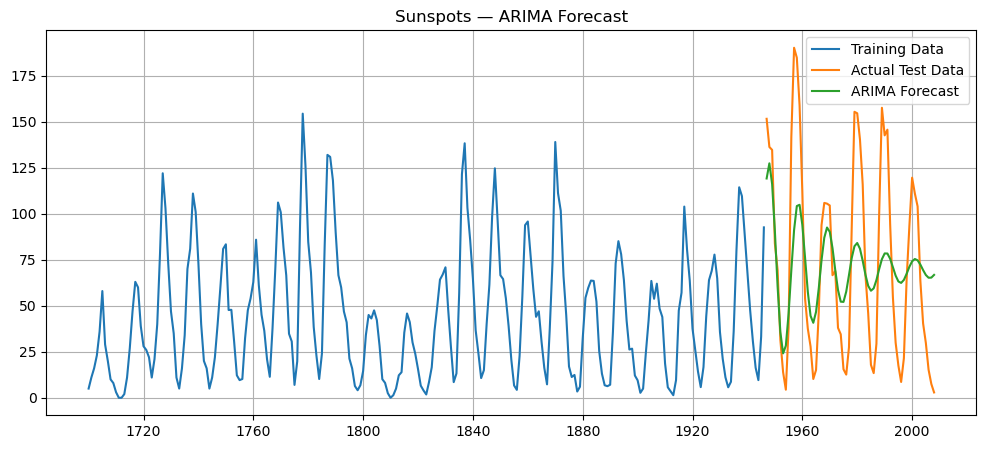

In [15]:
from statsmodels.datasets import sunspots

sun = sunspots.load_pandas().data.dropna().set_index("YEAR")["SUNACTIVITY"].astype(float)
sun.index = pd.to_datetime(sun.index.astype(int).astype(str), format="%Y")

sun_train_size = int(len(sun) * 0.80)
sun_train = sun.iloc[:sun_train_size]
sun_test = sun.iloc[sun_train_size:]

sun_model = ARIMA(sun_train, order=(2, 1, 2)).fit()
sun_forecast = sun_model.forecast(steps=len(sun_test))

sun_mae = mean_absolute_error(sun_test, sun_forecast)
sun_rmse = np.sqrt(mean_squared_error(sun_test, sun_forecast))

print("Dataset: Sunspots (statsmodels built-in dataset)")
print("Frequency: Annual")
print("Total observations:", len(sun))
print("Training observations:", len(sun_train))
print("Testing observations:", len(sun_test))
print("Selected order: (2, 1, 2)")
print("MAE:", sun_mae)
print("RMSE:", sun_rmse)

plt.figure(figsize=(12, 5))
plt.plot(sun_train, label="Training Data")
plt.plot(sun_test, label="Actual Test Data")
plt.plot(sun_forecast, label="ARIMA Forecast")
plt.title("Sunspots — ARIMA Forecast")
plt.legend()
plt.grid(True)
plt.show()

## 21. Lab Exercise 4 — Final Observation and Interpretation

The AirPassengers dataset contains an increasing trend and recurring seasonal fluctuations. The ADF test is used to assess stationarity, and first-order differencing is applied to reduce the trend. ACF and PACF plots help identify possible AR and MA orders. The data is split chronologically into training and testing sets so that future observations are not used during model fitting. The ARIMA model is trained on the training set and forecasts the unseen test period. MAE and RMSE are used to measure forecast error, while the residual plot helps assess whether unexplained patterns remain. The ARIMA order should be treated as a candidate and compared with alternatives using AIC and test-set performance.

# LAB EXERCISE 5 — SEASONAL ARIMA (SARIMA) FORECASTING

## 1. Aim
To implement a Seasonal ARIMA model for a dataset containing recurring seasonal patterns, identify the seasonal structure, fit a SARIMA model, generate forecasts and evaluate the predictions.

## 2. Theory
SARIMA extends ARIMA by explicitly modelling seasonality. It is represented as:

**SARIMA(p,d,q)(P,D,Q,s)**

- **p:** non-seasonal autoregressive order.
- **d:** non-seasonal differencing order.
- **q:** non-seasonal moving-average order.
- **P:** seasonal autoregressive order.
- **D:** seasonal differencing order.
- **Q:** seasonal moving-average order.
- **s:** seasonal period.

For monthly data with annual seasonality, s=12.

## 3. Seasonal Differencing
Seasonal differencing is:

\[
y'_t = y_t - y_{t-s}
\]

For monthly data with s=12, each month is compared with the same month in the previous year. This can reduce repeating annual seasonal patterns.

## 4. Why SARIMA?
A regular ARIMA model does not explicitly encode seasonal structure. SARIMA adds seasonal autoregressive, differencing and moving-average terms to model recurring patterns.

## 5. Import SARIMA Model

In [16]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

## 6. Load the Monthly AirPassengers Dataset and Set Frequency

In [17]:
sarima_df = pd.read_csv(url)
sarima_df["Month"] = pd.to_datetime(sarima_df["Month"])
sarima_df = sarima_df.set_index("Month")

seasonal_series = sarima_df["Passengers"].asfreq("MS").astype(float)

print(seasonal_series.head())
print("Frequency:", seasonal_series.index.freq)
print("Observations:", len(seasonal_series))

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64
Frequency: <MonthBegin>
Observations: 144


## 7. Plot the Original Seasonal Time Series

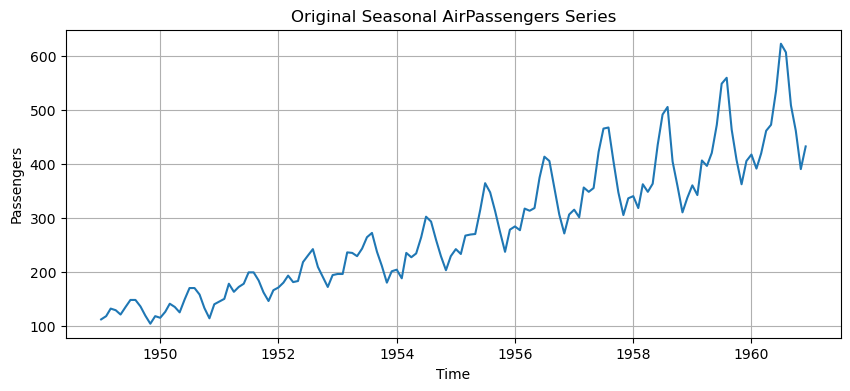

In [18]:
plt.figure()
plt.plot(seasonal_series)
plt.title("Original Seasonal AirPassengers Series")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

**Observation:** The series shows an upward trend and a repeating yearly pattern. Passenger counts tend to rise during particular months and decline during others, indicating annual seasonality.

## 8. Apply Seasonal Differencing (s=12)

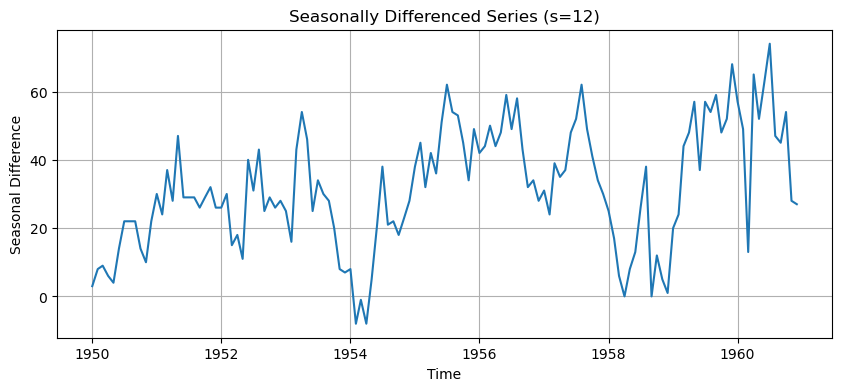

In [19]:
seasonal_diff = seasonal_series.diff(12).dropna()

plt.figure()
plt.plot(seasonal_diff)
plt.title("Seasonally Differenced Series (s=12)")
plt.xlabel("Time")
plt.ylabel("Seasonal Difference")
plt.grid(True)
plt.show()

**Observation:** Seasonal differencing compares each monthly value with the value from the same month one year earlier. This reduces the repeating annual pattern and helps prepare the series for seasonal modelling.

## 9. Plot ACF and PACF After Seasonal Differencing

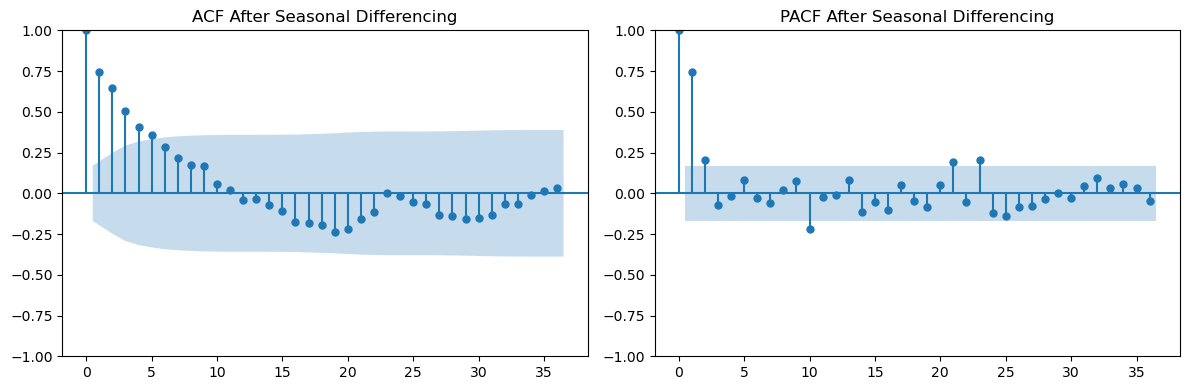

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(seasonal_diff, ax=axes[0], lags=36)
plot_pacf(seasonal_diff, ax=axes[1], lags=36, method="ywm")
axes[0].set_title("ACF After Seasonal Differencing")
axes[1].set_title("PACF After Seasonal Differencing")
plt.tight_layout()
plt.show()

**Observation:** The ACF and PACF plots help inspect correlations at ordinary and seasonal lags. They provide guidance for selecting candidate non-seasonal and seasonal orders.

## 10. Train-Test Split (80:20)

In [21]:
sarima_train_size = int(len(seasonal_series) * 0.80)
sarima_train = seasonal_series.iloc[:sarima_train_size]
sarima_test = seasonal_series.iloc[sarima_train_size:]

print("Training observations:", len(sarima_train))
print("Testing observations:", len(sarima_test))
print("Training period:", sarima_train.index.min(), "to", sarima_train.index.max())
print("Testing period:", sarima_test.index.min(), "to", sarima_test.index.max())

Training observations: 115
Testing observations: 29
Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


## 11. Fit SARIMA(1,1,1)(1,1,1,12)

In [22]:
sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)
print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Sun, 01 Nov 2026   AIC                            657.601
Time:                                    20:59:13   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

## 12. Forecast and Evaluate SARIMA

In [23]:
sarima_forecast = sarima_fit.forecast(steps=len(sarima_test))

sarima_mae = mean_absolute_error(sarima_test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(sarima_test, sarima_forecast))

print("SARIMA order: (1, 1, 1)")
print("Seasonal order: (1, 1, 1, 12)")
print("MAE:", sarima_mae)
print("RMSE:", sarima_rmse)

SARIMA order: (1, 1, 1)
Seasonal order: (1, 1, 1, 12)
MAE: 25.2680456878996
RMSE: 31.787297490441524


## 13. Plot SARIMA Forecast vs Actual Values

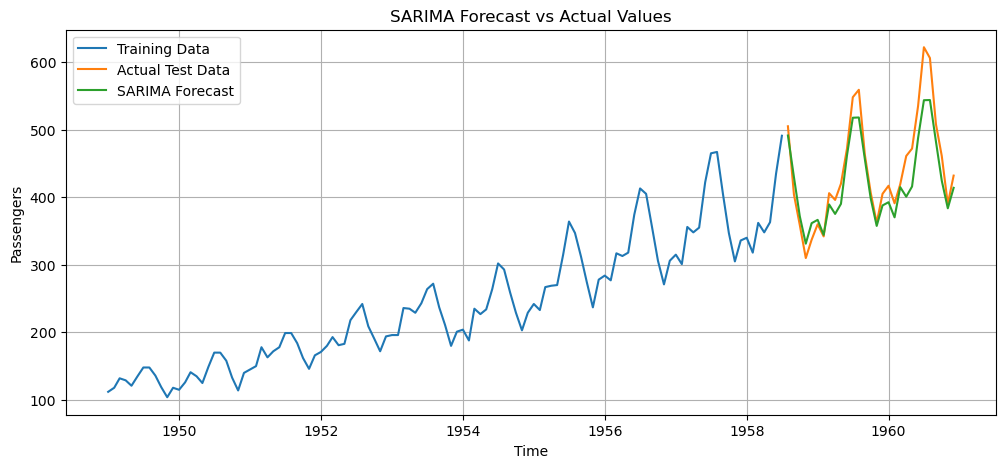

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(sarima_train.index, sarima_train, label="Training Data")
plt.plot(sarima_test.index, sarima_test, label="Actual Test Data")
plt.plot(sarima_test.index, sarima_forecast, label="SARIMA Forecast")
plt.title("SARIMA Forecast vs Actual Values")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()

## 14. SARIMA Residual Plot

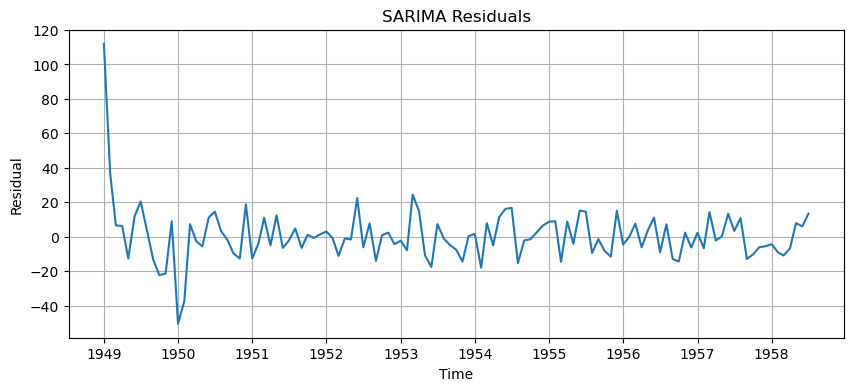

In [25]:
sarima_residuals = sarima_fit.resid

plt.figure()
plt.plot(sarima_residuals)
plt.title("SARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

**Observation:** The residual plot shows the errors remaining after fitting SARIMA. A good model should leave residuals without a systematic trend or repeating seasonal pattern.

## 15. Independent Task 5.1 — Compare at Least Three SARIMA Configurations

In [26]:
sarima_configs = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((2, 1, 1), (1, 1, 0, 12))
]

sarima_comparison = []

for order, seasonal_order in sarima_configs:
    fit = SARIMAX(
        sarima_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    prediction = fit.forecast(steps=len(sarima_test))
    sarima_comparison.append({
        "Order": str(order),
        "Seasonal Order": str(seasonal_order),
        "AIC": fit.aic,
        "MAE": mean_absolute_error(sarima_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(sarima_test, prediction))
    })

sarima_comparison_df = pd.DataFrame(sarima_comparison)
display(sarima_comparison_df)

,Order,Seasonal Order,AIC,MAE,RMSE
0,"(1, 1, 1)","(1, 1, 1, 12)",657.601346,25.268046,31.787297
1,"(0, 1, 1)","(0, 1, 1, 12)",659.341569,24.059215,30.580049
2,"(2, 1, 1)","(1, 1, 0, 12)",660.913752,22.193643,28.734509


## 16. Independent Task 5.2 — Explain Seasonal Period

- **s=12:** appropriate for monthly observations with a yearly seasonal cycle (12 months).
- **s=7:** appropriate for daily observations with a weekly pattern (7 days).
- **s=24:** appropriate for hourly observations with a daily cycle (24 hours).

## 17. Independent Task 5.3 — Compare ARIMA and SARIMA on the Same Test Set

In [27]:
# Use the same AirPassengers training and testing observations for both models.
comparison_df = pd.DataFrame([
    {
        "Model": "ARIMA(2,1,2)",
        "MAE": mean_absolute_error(test, arima_forecast),
        "RMSE": np.sqrt(mean_squared_error(test, arima_forecast))
    },
    {
        "Model": "SARIMA(1,1,1)(1,1,1,12)",
        "MAE": mean_absolute_error(sarima_test, sarima_forecast),
        "RMSE": np.sqrt(mean_squared_error(sarima_test, sarima_forecast))
    }
])
display(comparison_df)

,Model,MAE,RMSE
0,"ARIMA(2,1,2)",63.545311,82.513011
1,"SARIMA(1,1,1)(1,1,1,12)",25.268046,31.787297


**Note:** Both models use the same chronological AirPassengers 80:20 split. The model with lower MAE and RMSE has lower forecast error on this test period.

## 18. Independent Task 5.4 — Compare Seasonal Differencing D=0 and D=1

In [28]:
seasonal_d_results = []

for D in [0, 1]:
    fit = SARIMAX(
        sarima_train,
        order=(1, 1, 1),
        seasonal_order=(1, D, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    prediction = fit.forecast(steps=len(sarima_test))
    seasonal_d_results.append({
        "D": D,
        "AIC": fit.aic,
        "MAE": mean_absolute_error(sarima_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(sarima_test, prediction))
    })

display(pd.DataFrame(seasonal_d_results))

,D,AIC,MAE,RMSE
0,0,721.684158,18.697311,22.399179
1,1,657.601346,25.268046,31.787297


**Explanation:** D=0 does not apply seasonal differencing, while D=1 compares each observation with the observation from the same season in the previous year. Seasonal differencing can reduce annual seasonal structure when it is present. Compare the metrics and plots to assess its effect.

## 19. Independent Task 5.5 — Different Seasonal Dataset (Atmospheric CO₂)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Dataset: Atmospheric CO2 (statsmodels built-in dataset)
Original frequency: Weekly
Processed frequency: Monthly means
Seasonal period: s=12 (annual cycle in monthly data)
Total observations: 526
Training observations: 420
Testing observations: 106
MAE: 1.8527733870893246
RMSE: 2.184325973911014


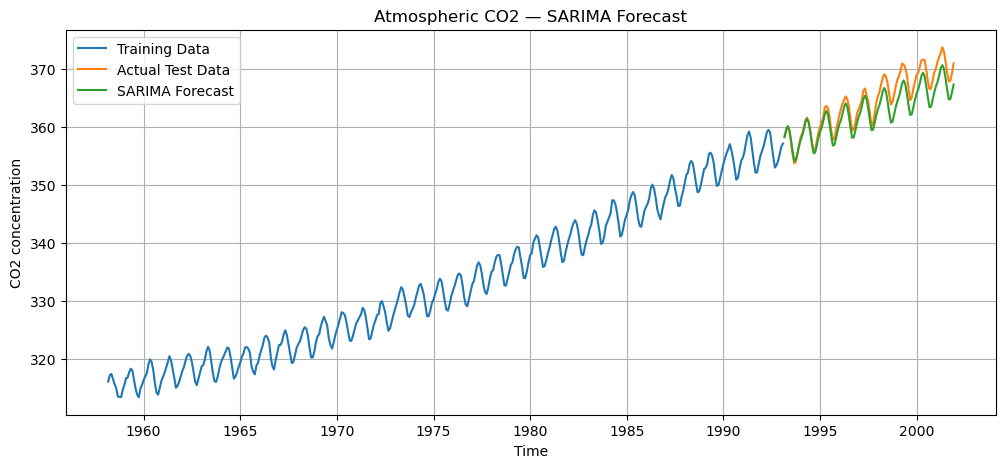

In [29]:
from statsmodels.datasets import co2

# Original dataset is weekly; resample it to monthly means and interpolate missing values.
co2_series = co2.load_pandas().data["co2"].resample("MS").mean().interpolate()

co2_train_size = int(len(co2_series) * 0.80)
co2_train = co2_series.iloc[:co2_train_size]
co2_test = co2_series.iloc[co2_train_size:]

co2_model = SARIMAX(
    co2_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

co2_forecast = co2_model.forecast(steps=len(co2_test))
co2_mae = mean_absolute_error(co2_test, co2_forecast)
co2_rmse = np.sqrt(mean_squared_error(co2_test, co2_forecast))

print("Dataset: Atmospheric CO2 (statsmodels built-in dataset)")
print("Original frequency: Weekly")
print("Processed frequency: Monthly means")
print("Seasonal period: s=12 (annual cycle in monthly data)")
print("Total observations:", len(co2_series))
print("Training observations:", len(co2_train))
print("Testing observations:", len(co2_test))
print("MAE:", co2_mae)
print("RMSE:", co2_rmse)

plt.figure(figsize=(12, 5))
plt.plot(co2_train, label="Training Data")
plt.plot(co2_test, label="Actual Test Data")
plt.plot(co2_forecast, label="SARIMA Forecast")
plt.title("Atmospheric CO2 — SARIMA Forecast")
plt.xlabel("Time")
plt.ylabel("CO2 concentration")
plt.legend()
plt.grid(True)
plt.show()

## 20. Lab Exercise 5 — Final Observation and Interpretation

The AirPassengers series contains a clear recurring annual pattern along with an upward trend. Seasonal differencing with s=12 compares each month with the same month in the previous year and reduces the yearly seasonal structure. ACF and PACF plots help inspect ordinary and seasonal lag relationships. The SARIMA model uses both non-seasonal and seasonal parameters to capture these patterns. The model is fitted only on the training observations and forecasts the held-out test period. MAE and RMSE measure the difference between forecast and actual passenger counts, while the residual plot helps identify remaining structure. Alternative SARIMA configurations and D values should be compared on the same test set before selecting a final model.

# OVERALL CONCLUSION

ARIMA and SARIMA are time-series forecasting models that use past observations and error relationships to predict future values. ARIMA is suitable for modelling non-seasonal patterns after appropriate differencing, while SARIMA additionally models repeating seasonal patterns. The experiments demonstrate data inspection, stationarity assessment, differencing, ACF/PACF analysis, chronological train-test splitting, model fitting, forecasting, evaluation using MAE and RMSE, and residual analysis. Comparing alternative model configurations helps select a more suitable forecasting model.

**Submission reminder:** Include the executed code, plots, metrics and observations. Fill in your name, USN, section and date before submission.